# Lab Assignment: Landmark Recognition Using the SIFT Algorithm

**Goal:** build a tourism-information style system that recognises a famous landmark in a query photo by matching
**SIFT** features against a database of reference images, localises the landmark with a **RANSAC homography**, and
rejects images that do not belong to the database.

| Task | Content |
|---|---|
| 1 | Landmark image database (≥ 5 landmarks, several views each) |
| 2 | SIFT feature extraction for reference images + storage of descriptors |
| 3 | Query image processing |
| 4 | Brute-force KNN matching (k = 2), Lowe's ratio test, ranking, threshold-based rejection |
| 5 | Landmark localisation (RANSAC homography + projected polygon) |
| 6 | Performance evaluation (6 test conditions) + results table + discussion |

### Folder layout expected next to this notebook
```
landmark_database/
    Eiffel_Tower/          eiffel_1.jpg, eiffel_2.jpg, ...
    Taj_Mahal/             ...
    Great_Wall_of_China/   ...
    Statue_of_Liberty/     ...
    Colosseum/             ...
query_images/
    original_query.jpg         <- a photo of one database landmark (NOT inside landmark_database/)
    different_viewpoint.jpg    <- (optional) real photo from another viewpoint; simulated if missing
    unknown_landmark.jpg       <- a landmark that is NOT in the database
```
Put **3 or more** images per landmark (different angles / distances / lighting). The folder name is the label.
Only the two paths in the configuration cell below (`ORIGINAL_QUERY`, `UNKNOWN_QUERY`) need to exist for Task 6.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Imports and configuration

In [3]:
import time
import pickle
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

# ----------------------------- paths -----------------------------
BASE_DRIVE_DIR = Path("/content/drive/MyDrive/Landmark_Recognition_SIFT_Complete")
DB_DIR        = BASE_DRIVE_DIR / "landmark_database"          # one sub-folder per landmark
QUERY_DIR     = BASE_DRIVE_DIR / "query_images"
RESULTS_DIR   = Path("results")                    # screenshots + CSV are saved here
DESCRIPTOR_FILE = RESULTS_DIR / "sift_descriptor_database.pkl"

# ----------------------------- Task 6 test inputs -----------------------------
ORIGINAL_QUERY     = QUERY_DIR / "original_query.jpg"
GROUND_TRUTH       = "Eiffel_Tower"                # label of ORIGINAL_QUERY (must match a database folder name)
VIEWPOINT_QUERY    = QUERY_DIR / "different_viewpoint.jpg"   # optional real photo, simulated if absent
UNKNOWN_QUERY      = QUERY_DIR / "unknown_landmark.jpg"

# ----------------------------- algorithm parameters -----------------------------
IMAGE_MAX_DIM            = 1000   # longest image side is limited to this (speed / consistent scale)
LOWE_RATIO               = 0.75   # Lowe's ratio test threshold
MIN_GOOD_MATCHES         = 15     # minimum reliable matches to even consider a landmark
MATCH_MARGIN             = 1.5    # best landmark must have >= 1.5x the matches of the runner-up (Task 4)
MIN_MATCHES_FOR_H        = 10     # minimum reliable matches before a homography is attempted
RANSAC_REPROJ_THRESH     = 5.0    # pixels
MIN_INLIERS              = 15     # minimum RANSAC inliers to accept geometric verification
MIN_INLIER_RATIO         = 0.15   # inliers / reliable matches (many matches but few consistent ones = coincidence)
INLIER_MARGIN            = 1.5    # best landmark inliers must be >= 1.5x the runner-up's inliers
MIN_POLY_AREA_RATIO      = 0.01   # projected polygon area relative to the query area (lower bound)
MAX_POLY_AREA_RATIO      = 8.0    # ... and upper bound
MAX_EDGE_RATIO           = 10.0   # longest / shortest polygon edge (rejects degenerate quads)
IMAGE_EXTENSIONS         = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

RESULTS_DIR.mkdir(exist_ok=True)

# ----------------------------- shared objects -----------------------------
sift    = cv2.SIFT_create()                          # SIFT detector / descriptor
matcher = cv2.BFMatcher(cv2.NORM_L2)                 # brute force, Euclidean (L2) distance


def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

OpenCV version: 4.14.0


## Task 1 – Landmark Image Database

Reference images are organised as `landmark_database/<Landmark_Name>/<image files>`.
The cell below scans the folders, checks the requirements (≥ 5 landmarks, several images each)
and shows a sample grid of the database.

,Landmark,Images
0,Colosseum,4
1,Eiffel_Tower,4
2,Great_Wall_of_China,4
3,Statue_of_Liberty,4
4,Taj_Mahal,4


Total landmarks: 5 | Total reference images: 20


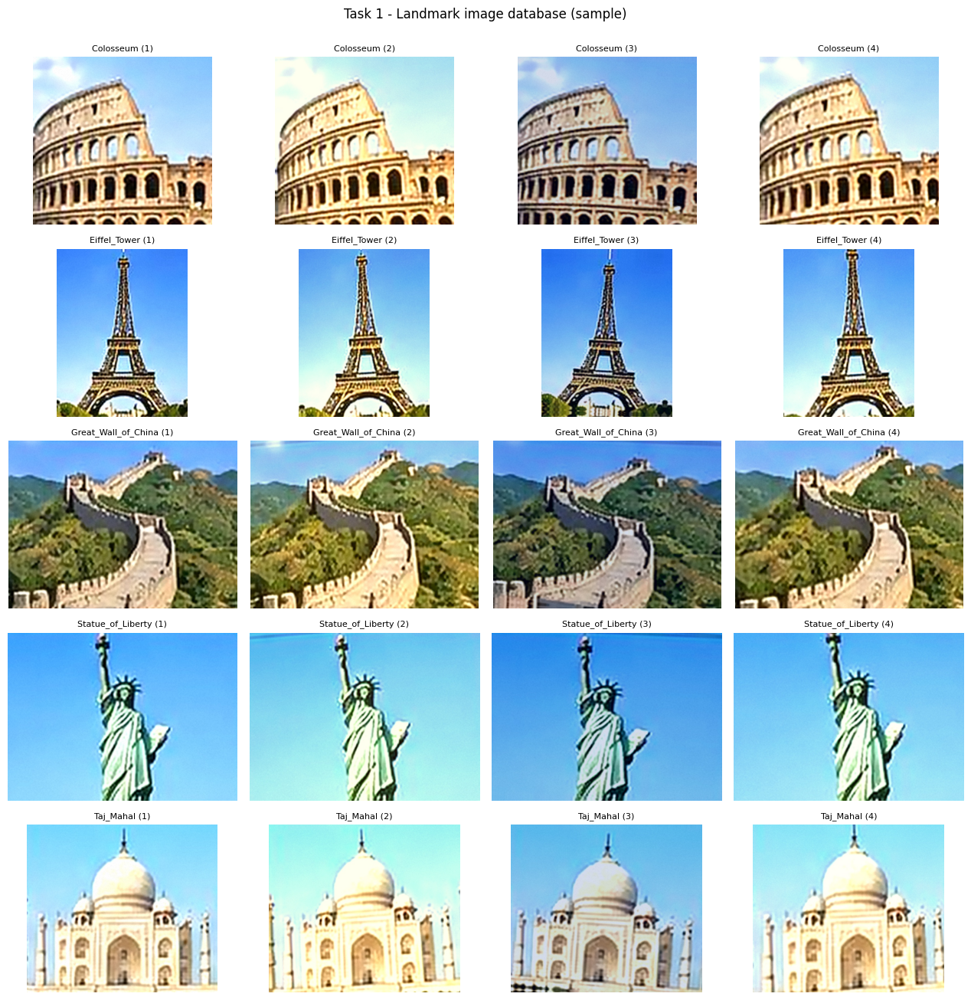

In [4]:
def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)


def load_image(path, max_dim=IMAGE_MAX_DIM):
    '''Read an image (BGR) and downscale it so its longest side is <= max_dim.'''
    img = cv2.imread(str(path))
    if img is None:
        raise IOError(f"Could not read image: {path}")
    scale = max_dim / max(img.shape[:2])
    if scale < 1.0:
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return img


def inspect_database(db_dir=DB_DIR):
    if not Path(db_dir).exists():
        raise FileNotFoundError(
            f"'{db_dir}' not found. Create it and add one sub-folder per landmark "
            "(e.g. landmark_database/Eiffel_Tower/eiffel_1.jpg).")
    folders = sorted(p for p in Path(db_dir).iterdir() if p.is_dir())
    rows = [{"Landmark": f.name, "Images": len(list_images(f))} for f in folders]
    table = pd.DataFrame(rows)
    if len(table) < 5:
        print(f"WARNING: only {len(table)} landmarks found - the assignment requires at least 5.")
    for _, r in table.iterrows():
        if r["Images"] < 2:
            print(f"WARNING: '{r['Landmark']}' has {r['Images']} image(s) - use several views per landmark.")
    return table


db_summary = inspect_database()
display(db_summary)
print(f"Total landmarks: {len(db_summary)} | Total reference images: {db_summary['Images'].sum()}")

# ---- sample grid: up to 4 images per landmark ----
landmark_names = db_summary["Landmark"].tolist()
cols = 4
fig, axes = plt.subplots(len(landmark_names), cols, figsize=(3.2 * cols, 2.6 * len(landmark_names)), squeeze=False)
for r, name in enumerate(landmark_names):
    imgs = list_images(DB_DIR / name)
    for c in range(cols):
        ax = axes[r][c]
        ax.axis("off")
        if c < len(imgs):
            ax.imshow(bgr2rgb(load_image(imgs[c], 400)))
            ax.set_title(f"{name} ({c + 1})", fontsize=8)
plt.suptitle("Task 1 - Landmark image database (sample)", y=1.0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_database_overview.png", dpi=120, bbox_inches="tight")
plt.show()

## Task 2 – SIFT Feature Extraction (reference images)

For every reference image: load → convert to grayscale → detect SIFT keypoints → compute 128-dimensional descriptors.
The keypoints, descriptors and the landmark label are stored in a dictionary
`database[landmark] = [ {file, image, keypoints, descriptors}, ... ]` and also saved to disk (`pickle`).

In [5]:
def extract_sift(img_bgr):
    '''Grayscale conversion + SIFT detection + descriptor extraction.'''
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    return gray, keypoints, descriptors


def build_database(db_dir=DB_DIR):
    database = {}
    for folder in sorted(p for p in Path(db_dir).iterdir() if p.is_dir()):
        entries = []
        for path in list_images(folder):
            img = load_image(path)
            _, kp, des = extract_sift(img)
            if des is None or len(kp) == 0:
                print(f"  skipped (no features): {path.name}")
                continue
            entries.append({"file": path.name, "path": str(path.resolve()), "image": img,
                            "keypoints": kp, "descriptors": des})
        database[folder.name] = entries
    return database


# ---- serialisation helpers (cv2.KeyPoint objects cannot be pickled directly) ----
def keypoints_to_tuples(kps):
    return [(k.pt, k.size, k.angle, k.response, k.octave, k.class_id) for k in kps]


def tuples_to_keypoints(tuples):
    return [cv2.KeyPoint(x=p[0], y=p[1], size=s, angle=a, response=r, octave=o, class_id=c)
            for (p, s, a, r, o, c) in tuples]


def save_descriptor_database(database, file=DESCRIPTOR_FILE):
    serial = {name: [{"file": e["file"], "path": e["path"],
                      "keypoints": keypoints_to_tuples(e["keypoints"]),
                      "descriptors": e["descriptors"]} for e in entries]
              for name, entries in database.items()}
    with open(file, "wb") as f:
        pickle.dump(serial, f)


def load_descriptor_database(file=DESCRIPTOR_FILE):
    with open(file, "rb") as f:
        serial = pickle.load(f)
    return {name: [{"file": e["file"], "path": e["path"], "image": load_image(e["path"]),
                    "keypoints": tuples_to_keypoints(e["keypoints"]),
                    "descriptors": e["descriptors"]} for e in entries]
            for name, entries in serial.items()}


t0 = time.perf_counter()
database = build_database()
print(f"Feature extraction finished in {time.perf_counter() - t0:.2f} s\n")

stats = pd.DataFrame([{"Landmark": n, "Images": len(e),
                       "Total keypoints": sum(len(x["keypoints"]) for x in e),
                       "Avg keypoints / image": round(np.mean([len(x["keypoints"]) for x in e]), 1) if e else 0,
                       "Descriptor shape": e[0]["descriptors"].shape[1:] if e else None}
                      for n, e in database.items()])
display(stats)

# ---- store descriptors with labels, then reload them to prove the stored database works ----
save_descriptor_database(database)
database = load_descriptor_database()
print(f"Descriptors saved to '{DESCRIPTOR_FILE}' and reloaded ({sum(len(v) for v in database.values())} images).")

Feature extraction finished in 2.20 s



,Landmark,Images,Total keypoints,Avg keypoints / image,Descriptor shape
0,Colosseum,4,3662,915.5,"(128,)"
1,Eiffel_Tower,4,3293,823.2,"(128,)"
2,Great_Wall_of_China,4,6628,1657.0,"(128,)"
3,Statue_of_Liberty,4,1516,379.0,"(128,)"
4,Taj_Mahal,4,2448,612.0,"(128,)"


Descriptors saved to 'results/sift_descriptor_database.pkl' and reloaded (20 images).


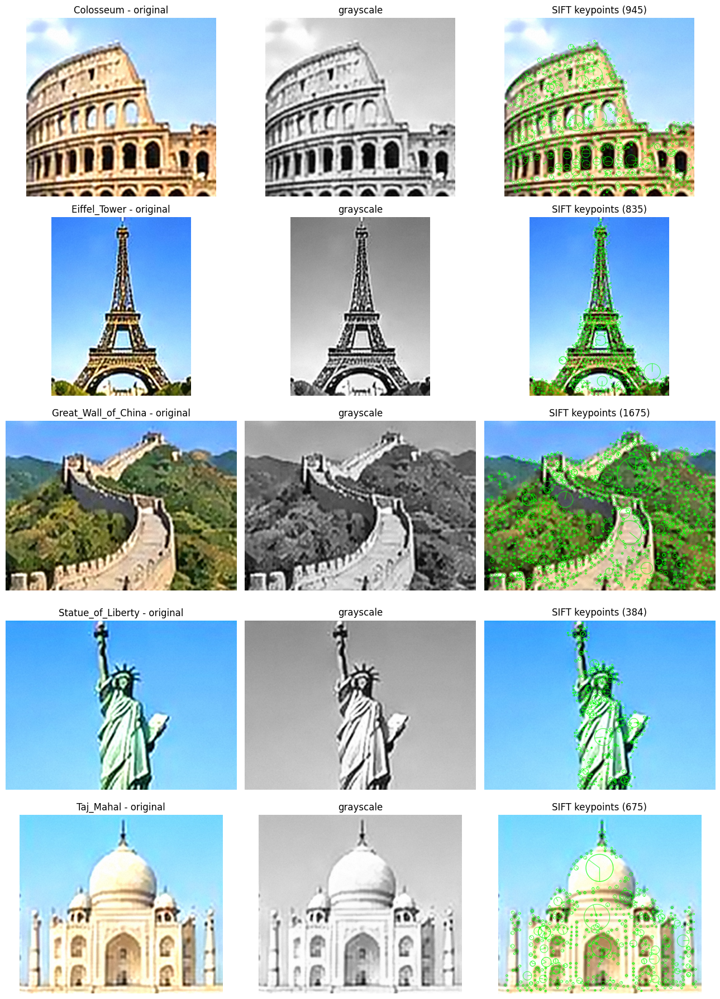

Descriptor matrix shape (keypoints x 128): (945, 128)
First descriptor (first 12 values): [ 0.  0.  5. 43. 57. 96. 24.  0. 13.  4. 11.  5.]


In [6]:
# ---- display reference images with their detected keypoints (one view per landmark + grayscale) ----
names = [n for n in database if database[n]]
fig, axes = plt.subplots(len(names), 3, figsize=(13, 3.6 * len(names)), squeeze=False)
for r, name in enumerate(names):
    e = database[name][0]
    gray = cv2.cvtColor(e["image"], cv2.COLOR_BGR2GRAY)
    vis = cv2.drawKeypoints(e["image"], e["keypoints"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
                            color=(0, 255, 0))
    axes[r][0].imshow(bgr2rgb(e["image"]));  axes[r][0].set_title(f"{name} - original")
    axes[r][1].imshow(gray, cmap="gray");    axes[r][1].set_title("grayscale")
    axes[r][2].imshow(bgr2rgb(vis));         axes[r][2].set_title(f"SIFT keypoints ({len(e['keypoints'])})")
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task2_reference_keypoints.png", dpi=120, bbox_inches="tight")
plt.show()

# ---- what one descriptor looks like ----
e0 = database[names[0]][0]
print("Descriptor matrix shape (keypoints x 128):", e0["descriptors"].shape)
print("First descriptor (first 12 values):", np.round(e0["descriptors"][0][:12], 2))

## Task 3 – Query Image Processing

`process_query()` loads an unknown image, converts it to grayscale, detects SIFT keypoints and extracts the
descriptors. The query image is displayed together with its keypoints.

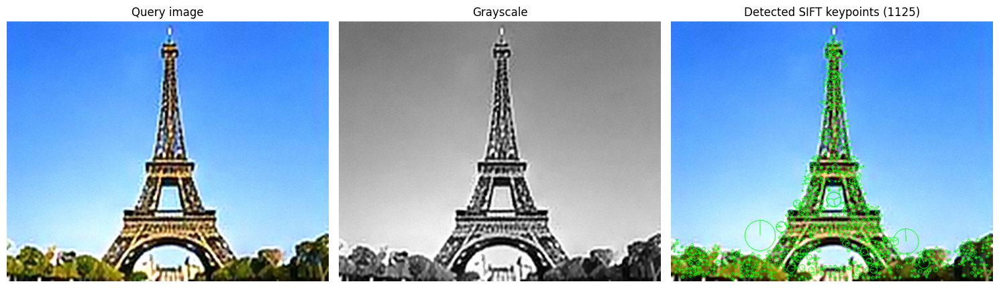

Query descriptors: (1125, 128)


In [7]:
def process_query(source, show=True):
    '''source: file path or an already loaded BGR image.'''
    img = load_image(source) if isinstance(source, (str, Path)) else source
    gray, kp, des = extract_sift(img)
    if show:
        vis = cv2.drawKeypoints(img, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS, color=(0, 255, 0))
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
        ax[0].imshow(bgr2rgb(img));        ax[0].set_title("Query image")
        ax[1].imshow(gray, cmap="gray");   ax[1].set_title("Grayscale")
        ax[2].imshow(bgr2rgb(vis));        ax[2].set_title(f"Detected SIFT keypoints ({len(kp)})")
        for a in ax:
            a.axis("off")
        plt.tight_layout()
        plt.show()
    return {"image": img, "gray": gray, "keypoints": kp, "descriptors": des}


if ORIGINAL_QUERY.exists():
    demo_query = process_query(ORIGINAL_QUERY)
    print("Query descriptors:", None if demo_query["descriptors"] is None else demo_query["descriptors"].shape)
else:
    print(f"Put a query photo at '{ORIGINAL_QUERY}' (or change ORIGINAL_QUERY in the configuration cell).")

## Task 4 – Feature Matching and Landmark Recognition

1. **Brute-Force matcher, Euclidean (L2) distance** – `cv2.BFMatcher(cv2.NORM_L2)`
2. **KNN matching, k = 2** – the two nearest reference descriptors for each query descriptor
3. **Lowe's ratio test** – keep a match only if `d1 < 0.75 · d2` (removes ambiguous matches)
4. **Count reliable matches** for every reference image; a landmark's score is its best reference image
5. **Rank** the landmark candidates
6. **Decision:** the largest match count alone is *not* used. A landmark is only accepted when
   (a) it has at least `MIN_GOOD_MATCHES` reliable matches, **and**
   (b) it clearly beats the runner-up (`MATCH_MARGIN`).
   The geometric check of Task 5 is added on top of this in the final pipeline.

,Rank,Landmark,Best reference image,Reliable matches
0,1,Eiffel_Tower,eiffel_1.jpg,794
1,2,Great_Wall_of_China,great_wall_2.jpg,13
2,3,Statue_of_Liberty,statue_2.jpg,10
3,4,Colosseum,colosseum_3.jpg,7
4,5,Taj_Mahal,taj_2.jpg,7


Most likely landmark: Eiffel_Tower  |  reliable matches: 794
Match-count decision: accepted by match count   (matching time 0.50 s)


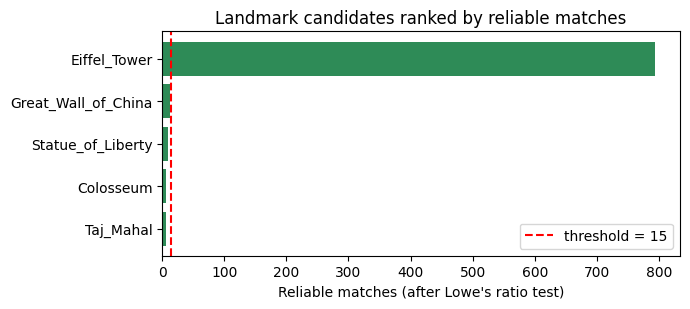

In [8]:
def ratio_test_match(des_query, des_ref, ratio=LOWE_RATIO):
    '''BF + KNN (k=2) + Lowe's ratio test. queryIdx -> query keypoint, trainIdx -> reference keypoint.'''
    if des_query is None or des_ref is None or len(des_query) < 2 or len(des_ref) < 2:
        return []
    pairs = matcher.knnMatch(des_query, des_ref, k=2)
    return [p[0] for p in pairs if len(p) == 2 and p[0].distance < ratio * p[1].distance]


def match_against_database(des_query, database, exclude_path=None):
    '''Match the query against every reference image of every landmark.'''
    results = []
    for landmark, entries in database.items():
        for e in entries:
            if exclude_path is not None and e["path"] == exclude_path:
                continue                                  # used for leave-one-out testing
            results.append({"landmark": landmark, "entry": e,
                            "good": ratio_test_match(des_query, e["descriptors"])})
    return results


def rank_by_matches(per_image):
    '''One row per landmark (its best reference image), sorted by number of reliable matches.'''
    best = {}
    for r in per_image:
        if r["landmark"] not in best or len(r["good"]) > len(best[r["landmark"]]["good"]):
            best[r["landmark"]] = r
    return sorted(best.values(), key=lambda r: len(r["good"]), reverse=True)


def decide_by_matches(ranking):
    '''Threshold + margin decision (no geometry yet). Returns (accepted, reason).'''
    top = len(ranking[0]["good"])
    second = len(ranking[1]["good"]) if len(ranking) > 1 else 0
    if top < MIN_GOOD_MATCHES:
        return False, f"rejected: only {top} reliable matches (< {MIN_GOOD_MATCHES})"
    if top < MATCH_MARGIN * second:
        return False, f"rejected: ambiguous ({top} vs {second} matches for the runner-up)"
    return True, "accepted by match count"


def ranking_table(ranking):
    return pd.DataFrame([{"Rank": i + 1, "Landmark": r["landmark"], "Best reference image": r["entry"]["file"],
                          "Reliable matches": len(r["good"])} for i, r in enumerate(ranking)])


# ---- demo on the original query ----
if ORIGINAL_QUERY.exists():
    q = process_query(ORIGINAL_QUERY, show=False)
    t0 = time.perf_counter()
    per_image = match_against_database(q["descriptors"], database)
    ranking = rank_by_matches(per_image)
    elapsed = time.perf_counter() - t0
    display(ranking_table(ranking))
    accepted, reason = decide_by_matches(ranking)
    print(f"Most likely landmark: {ranking[0]['landmark']}  |  reliable matches: {len(ranking[0]['good'])}")
    print(f"Match-count decision: {reason}   (matching time {elapsed:.2f} s)")

    # bar chart of the ranking
    plt.figure(figsize=(7, 3.2))
    plt.barh([r["landmark"] for r in ranking][::-1], [len(r["good"]) for r in ranking][::-1], color="seagreen")
    plt.axvline(MIN_GOOD_MATCHES, color="red", ls="--", label=f"threshold = {MIN_GOOD_MATCHES}")
    plt.xlabel("Reliable matches (after Lowe's ratio test)")
    plt.title("Landmark candidates ranked by reliable matches")
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "task4_ranking.png", dpi=120)
    plt.show()
else:
    print("Original query image not found - see the configuration cell.")

## Task 5 – Landmark Localization (RANSAC homography)

For the candidate reference images with enough reliable matches:

1. collect the corresponding keypoint coordinates (reference ↔ query)
2. estimate a **homography with RANSAC** (`cv2.findHomography`)
3. project the **four corners** of the reference image into the query image
4. draw the polygon around the landmark
5. report the number of **reliable matches** and **RANSAC inliers**

The polygon is only accepted if it is a plausible quadrilateral (finite, convex, sensible size and shape).
If the geometry is unreliable a message is displayed instead of drawing an invalid polygon.

`recognize()` below is the complete final pipeline: SIFT → matching → ranking → geometric verification → decision.

,Rank,Landmark,Best reference image,Reliable matches,RANSAC inliers,Geometry valid
0,1,Eiffel_Tower,eiffel_1.jpg,794,787,True
1,2,Great_Wall_of_China,great_wall_2.jpg,13,4,False
2,3,Statue_of_Liberty,statue_2.jpg,10,4,False
3,4,Colosseum,colosseum_3.jpg,7,0,False
4,5,Taj_Mahal,taj_2.jpg,7,0,False


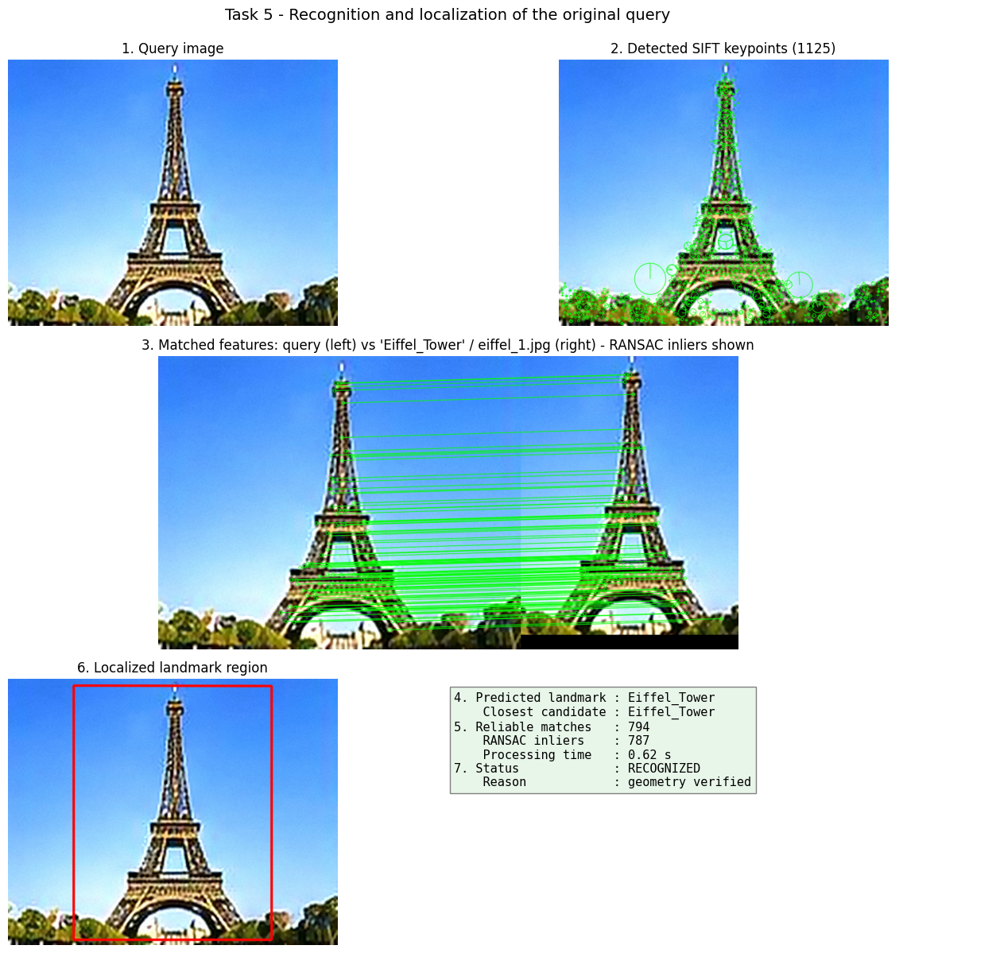

In [9]:
def is_valid_polygon(poly, query_shape):
    '''Plausibility checks for the projected reference-image corners.'''
    poly = np.asarray(poly, dtype=np.float32).reshape(4, 2)
    if not np.all(np.isfinite(poly)):
        return False, "projected corners are not finite"
    if not cv2.isContourConvex(poly.reshape(-1, 1, 2)):
        return False, "projected polygon is not convex"
    area = cv2.contourArea(poly.reshape(-1, 1, 2))
    q_area = query_shape[0] * query_shape[1]
    if not (MIN_POLY_AREA_RATIO * q_area <= area <= MAX_POLY_AREA_RATIO * q_area):
        return False, "projected polygon has an implausible size"
    edges = np.linalg.norm(poly - np.roll(poly, -1, axis=0), axis=1)
    if edges.min() < 5 or edges.max() / edges.min() > MAX_EDGE_RATIO:
        return False, "projected polygon is degenerate"
    return True, "ok"


def estimate_homography(kp_query, kp_ref, good, ref_shape, query_shape):
    '''RANSAC homography reference -> query and projection of the reference image corners.'''
    geo = {"H": None, "mask": None, "inliers": 0, "polygon": None, "valid": False, "message": ""}
    if len(good) < MIN_MATCHES_FOR_H:
        geo["message"] = f"not enough reliable matches for a homography ({len(good)} < {MIN_MATCHES_FOR_H})"
        return geo

    src = np.float32([kp_ref[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)     # reference points
    dst = np.float32([kp_query[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # query points
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_REPROJ_THRESH)
    if H is None or mask is None:
        geo["message"] = "RANSAC could not estimate a homography"
        return geo

    geo["H"], geo["mask"], geo["inliers"] = H, mask.ravel().astype(int), int(mask.sum())
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    polygon = cv2.perspectiveTransform(corners, H).reshape(4, 2)
    ok, why = is_valid_polygon(polygon, query_shape)
    geo["polygon"], geo["valid"] = polygon, ok
    geo["message"] = "geometry verified" if ok else f"geometric transformation unreliable: {why}"
    return geo


def recognize(query_bgr, database, exclude_path=None):
    '''Full pipeline. Returns a dictionary with everything needed for display and for the results table.'''
    t0 = time.perf_counter()
    q = process_query(query_bgr, show=False)
    kp_q, des_q = q["keypoints"], q["descriptors"]

    per_image = match_against_database(des_q, database, exclude_path)
    for r in per_image:                                   # geometric verification of every candidate image
        r["geo"] = estimate_homography(kp_q, r["entry"]["keypoints"], r["good"],
                                       r["entry"]["image"].shape, q["image"].shape)

    def score(r):                                         # verified inliers first, raw matches second
        return (r["geo"]["inliers"] if r["geo"]["valid"] else 0, len(r["good"]))

    best_per_landmark = {}
    for r in per_image:
        if r["landmark"] not in best_per_landmark or score(r) > score(best_per_landmark[r["landmark"]]):
            best_per_landmark[r["landmark"]] = r
    ranking = sorted(best_per_landmark.values(), key=score, reverse=True)

    best = ranking[0]
    second = ranking[1] if len(ranking) > 1 else None
    n_good, geo = len(best["good"]), best["geo"]
    inl, inl_second = score(best)[0], (score(second)[0] if second else 0)

    # ---- decision: threshold + geometry + margin (never just "largest count wins") ----
    if n_good < MIN_GOOD_MATCHES:
        recognized, reason = False, f"too few reliable matches ({n_good} < {MIN_GOOD_MATCHES})"
    elif not geo["valid"]:
        recognized, reason = False, geo["message"]
    elif inl < MIN_INLIERS:
        recognized, reason = False, f"too few RANSAC inliers ({inl} < {MIN_INLIERS})"
    elif inl < MIN_INLIER_RATIO * n_good:
        recognized, reason = False, f"low inlier ratio ({inl}/{n_good} = {inl / n_good:.0%} < {MIN_INLIER_RATIO:.0%})"
    elif inl < INLIER_MARGIN * inl_second:
        recognized, reason = False, f"ambiguous: {inl} inliers vs {inl_second} for '{second['landmark']}'"
    else:
        recognized, reason = True, "geometry verified"

    return {"query": q, "ranking": ranking, "best": best, "recognized": recognized, "reason": reason,
            "predicted": best["landmark"] if recognized else "Unknown (rejected)",
            "closest_candidate": best["landmark"], "n_keypoints": len(kp_q), "n_good": n_good,
            "inliers": geo["inliers"], "time_s": time.perf_counter() - t0}


def show_recognition(res, title="Recognition result", save_as=None, max_lines=100):
    '''Query, keypoints, matched features, predicted label and localisation (or a failure message).'''
    q, best, geo = res["query"], res["best"], res["best"]["geo"]
    ref = best["entry"]
    kp_vis = cv2.drawKeypoints(q["image"], q["keypoints"], None, color=(0, 255, 0),
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    good = best["good"]
    mask = geo["mask"] if geo["mask"] is not None else np.ones(len(good), dtype=int)
    order = np.argsort([m.distance for m in good])[:max_lines] if good else []
    sel = [good[i] for i in order]
    sel_mask = [int(mask[i]) for i in order]
    match_vis = cv2.drawMatches(q["image"], q["keypoints"], ref["image"], ref["keypoints"], sel, None,
                                matchColor=(0, 255, 0), singlePointColor=(255, 0, 0),
                                matchesMask=sel_mask if geo["valid"] else None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    loc = q["image"].copy()
    if res["recognized"]:
        thick = max(3, int(max(loc.shape[:2]) / 200))
        cv2.polylines(loc, [np.int32(geo["polygon"]).reshape(-1, 1, 2)], True, (0, 0, 255), thick, cv2.LINE_AA)
        loc_title = "Localized landmark region"
    else:
        loc_title = "Localization not available"

    fig = plt.figure(figsize=(14, 12))
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.1, 1])
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(bgr2rgb(q["image"])); ax.set_title("1. Query image"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(bgr2rgb(kp_vis));
    ax.set_title(f"2. Detected SIFT keypoints ({res['n_keypoints']})"); ax.axis("off")
    ax = fig.add_subplot(gs[1, :]); ax.imshow(bgr2rgb(match_vis))
    ax.set_title(f"3. Matched features: query (left) vs '{best['landmark']}' / {ref['file']} (right) - "
                 f"{'RANSAC inliers shown' if geo['valid'] else 'all reliable matches shown'}")
    ax.axis("off")
    ax = fig.add_subplot(gs[2, 0]); ax.imshow(bgr2rgb(loc)); ax.set_title(f"6. {loc_title}"); ax.axis("off")
    if not res["recognized"]:
        ax.text(0.5, 0.04, "Geometric verification failed - no polygon drawn", transform=ax.transAxes,
                ha="center", color="white", fontsize=10, bbox=dict(facecolor="red", alpha=0.8))

    ax = fig.add_subplot(gs[2, 1]); ax.axis("off")
    status = "RECOGNIZED" if res["recognized"] else "REJECTED"
    lines = [f"4. Predicted landmark : {res['predicted']}",
             f"    Closest candidate : {res['closest_candidate']}",
             f"5. Reliable matches   : {res['n_good']}",
             f"    RANSAC inliers    : {res['inliers']}",
             f"    Processing time   : {res['time_s']:.2f} s",
             f"7. Status             : {status}",
             f"    Reason            : {res['reason']}"]
    ax.text(0.0, 0.95, "\n".join(lines), va="top", family="monospace", fontsize=11,
            bbox=dict(facecolor="#e8f5e9" if res["recognized"] else "#ffebee", edgecolor="gray"))
    fig.suptitle(title, fontsize=14, y=0.995)
    plt.tight_layout()
    if save_as:
        plt.savefig(RESULTS_DIR / save_as, dpi=120, bbox_inches="tight")
    plt.show()


# ---- demo on the original query ----
if ORIGINAL_QUERY.exists():
    demo = recognize(load_image(ORIGINAL_QUERY), database)
    display(ranking_table(demo["ranking"]).assign(
        **{"RANSAC inliers": [r["geo"]["inliers"] for r in demo["ranking"]],
           "Geometry valid": [r["geo"]["valid"] for r in demo["ranking"]]}))
    show_recognition(demo, "Task 5 - Recognition and localization of the original query", "task5_localization.png")
else:
    print("Original query image not found - see the configuration cell.")

## Task 6 – Performance Evaluation

Six test conditions are evaluated. All variants are derived from the **original query image** so they are directly comparable:

| # | Test | How it is produced |
|---|---|---|
| 1 | Original | `ORIGINAL_QUERY` |
| 2 | Rotated | rotated by 45° (canvas enlarged, nothing cropped) |
| 3 | Resized | scaled to 50 % |
| 4 | Reduced brightness | pixel values multiplied by 0.35 |
| 5 | Different viewpoint | real photo `VIEWPOINT_QUERY` if present, otherwise a perspective warp of the original (simulated) |
| 6 | Unknown landmark | `UNKNOWN_QUERY` (not in the database → must be **rejected**) |

For each test the predicted landmark, number of keypoints, reliable matches, RANSAC inliers, decision and processing time are recorded.

In [10]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    new_w, new_h = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += new_w / 2 - w / 2
    M[1, 2] += new_h / 2 - h / 2
    return cv2.warpAffine(img, M, (new_w, new_h), borderValue=(0, 0, 0))


def resize_image(img, scale):
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def reduce_brightness(img, factor=0.35):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)


def simulate_viewpoint(img):
    '''Perspective warp that imitates photographing the scene from the side (used only if no real photo exists).'''
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32([[0.12 * w, 0.06 * h], [0.97 * w, 0.0], [0.90 * w, 0.96 * h], [0.05 * w, h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))


def build_test_set():
    if not ORIGINAL_QUERY.exists():
        raise FileNotFoundError(f"'{ORIGINAL_QUERY}' not found. Add a photo of a database landmark.")
    if not UNKNOWN_QUERY.exists():
        raise FileNotFoundError(f"'{UNKNOWN_QUERY}' not found. Add a photo of a landmark that is NOT in the database.")
    original = load_image(ORIGINAL_QUERY)
    if VIEWPOINT_QUERY.exists():
        viewpoint, vp_note = load_image(VIEWPOINT_QUERY), "real photo"
    else:
        viewpoint, vp_note = simulate_viewpoint(original), "simulated perspective warp"
    return [("Original",              original,                       GROUND_TRUTH, ""),
            ("Rotated (45 deg)",      rotate_image(original, 45),     GROUND_TRUTH, ""),
            ("Resized (50 %)",        resize_image(original, 0.5),    GROUND_TRUTH, ""),
            ("Reduced brightness",    reduce_brightness(original),    GROUND_TRUTH, ""),
            ("Different viewpoint",   viewpoint,                      GROUND_TRUTH, vp_note),
            ("Unknown landmark",      load_image(UNKNOWN_QUERY),      "Unknown",    "not in database")]


def run_evaluation(test_set, database):
    rows, results = [], []
    exclude = str(ORIGINAL_QUERY.resolve())               # never match the query against itself
    for name, img, truth, note in test_set:
        res = recognize(img, database, exclude_path=exclude)
        correct = (res["predicted"] == truth)
        rows.append({"Test": name, "Expected": truth, "Predicted": res["predicted"],
                     "Closest candidate": res["closest_candidate"], "Keypoints": res["n_keypoints"],
                     "Reliable matches": res["n_good"], "RANSAC inliers": res["inliers"],
                     "Decision": "Recognized" if res["recognized"] else "Rejected",
                     "Time (s)": round(res["time_s"], 3), "Correct": "Yes" if correct else "No", "Note": note})
        results.append(res)
    return pd.DataFrame(rows), results


test_set = build_test_set()
results_table, test_results = run_evaluation(test_set, database)
display(results_table)
results_table.to_csv(RESULTS_DIR / "task6_results.csv", index=False)

,Test,Expected,Predicted,Closest candidate,Keypoints,Reliable matches,RANSAC inliers,Decision,Time (s),Correct,Note
0,Original,Eiffel_Tower,Eiffel_Tower,Eiffel_Tower,1125,794,787,Recognized,0.619,Yes,
1,Rotated (45 deg),Eiffel_Tower,Eiffel_Tower,Eiffel_Tower,1178,686,677,Recognized,0.826,Yes,
2,Resized (50 %),Eiffel_Tower,Eiffel_Tower,Eiffel_Tower,1009,616,605,Recognized,0.486,Yes,
3,Reduced brightness,Eiffel_Tower,Eiffel_Tower,Eiffel_Tower,751,589,582,Recognized,0.454,Yes,
4,Different viewpoint,Eiffel_Tower,Eiffel_Tower,Eiffel_Tower,1040,658,645,Recognized,0.557,Yes,real photo
5,Unknown landmark,Unknown,Unknown (rejected),Eiffel_Tower,427,14,4,Rejected,0.314,No,not in database


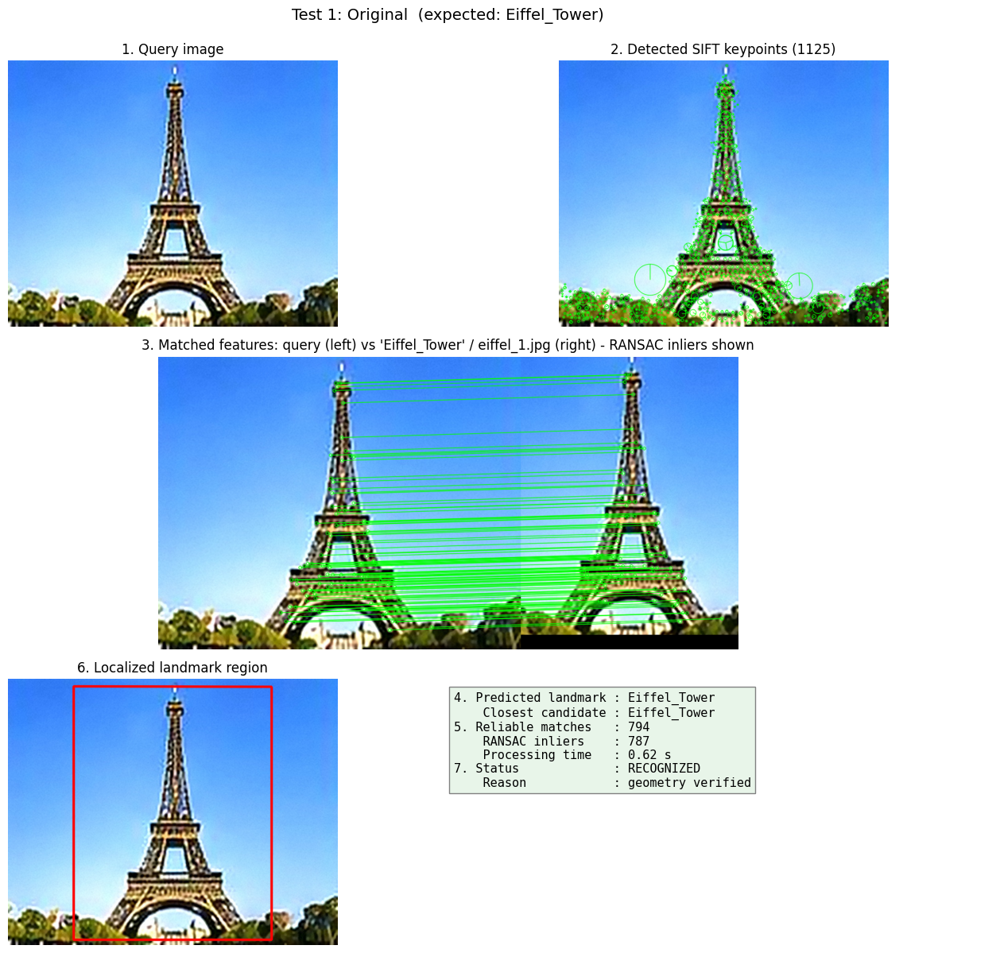

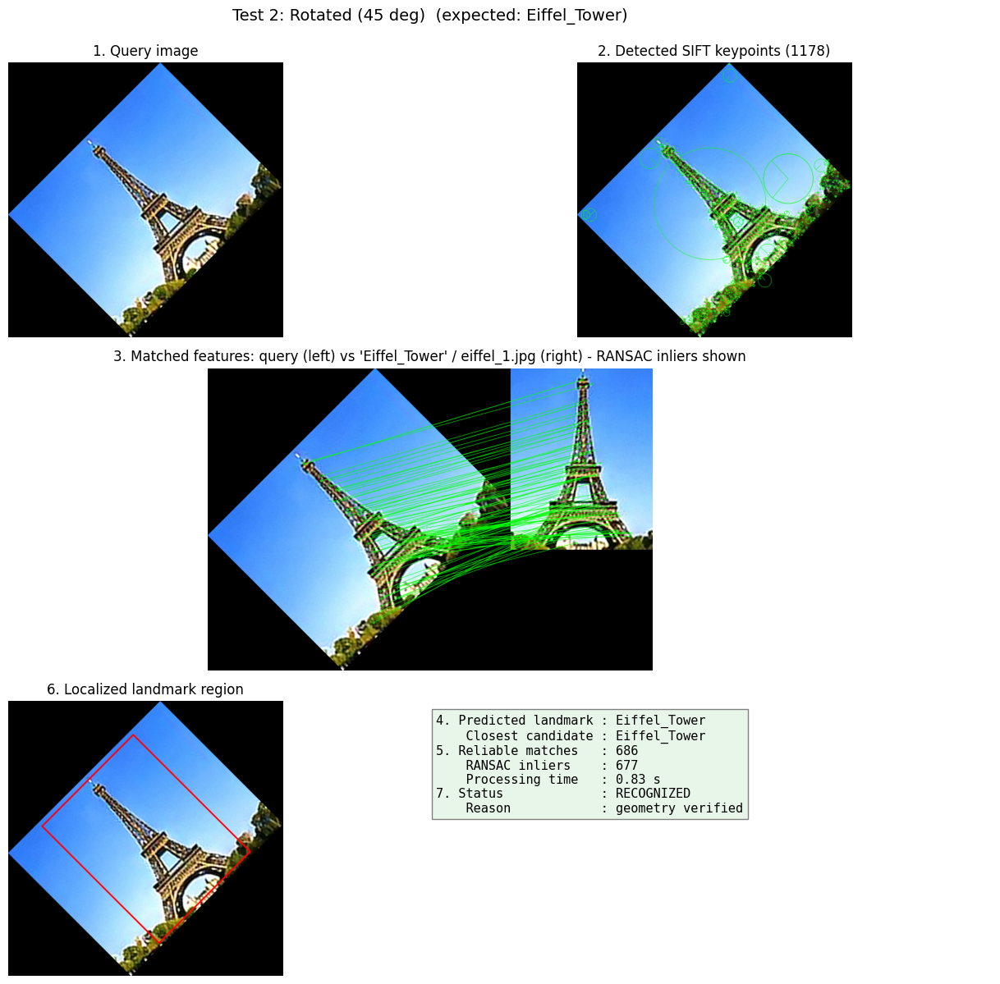

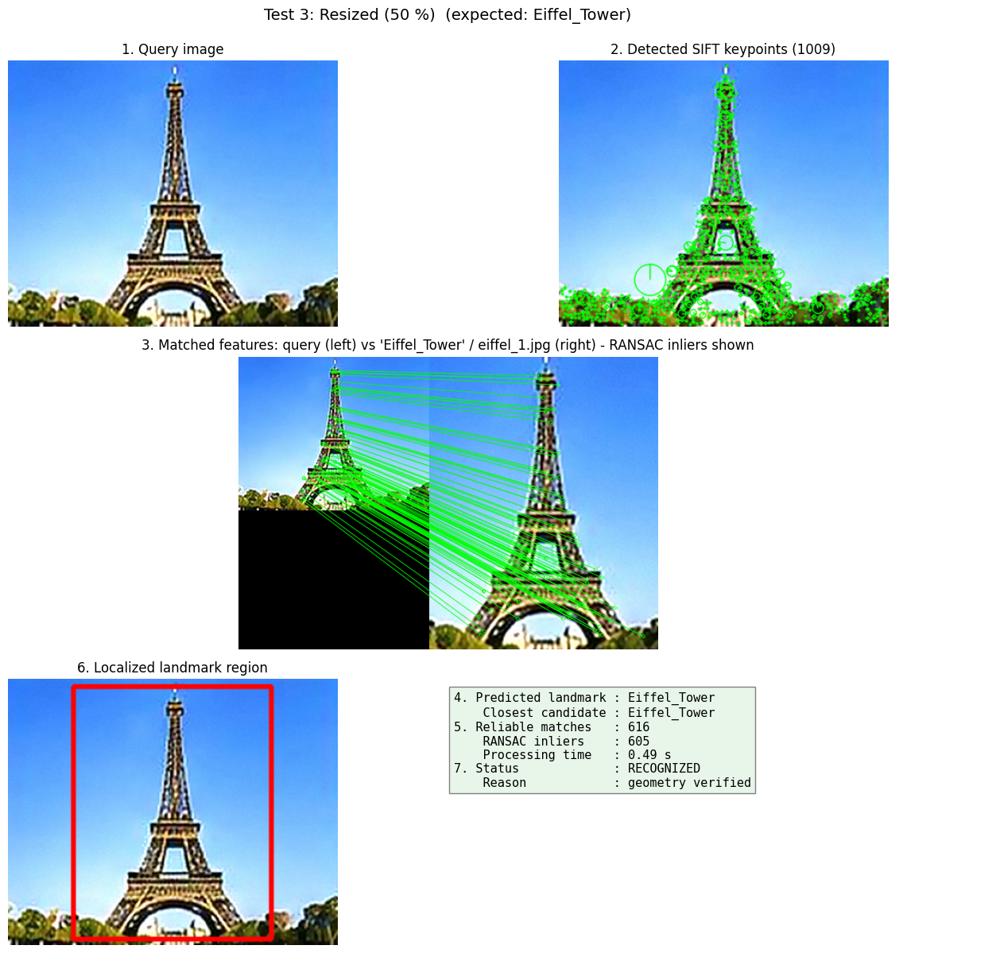

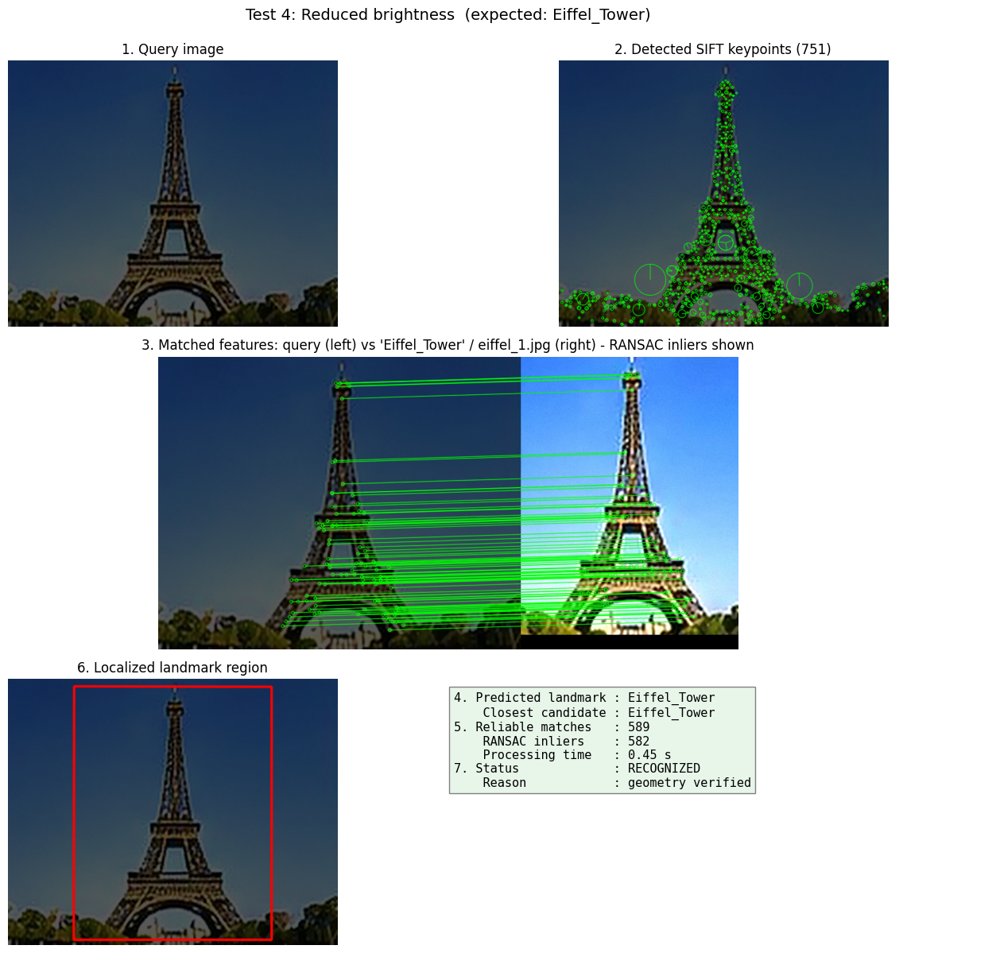

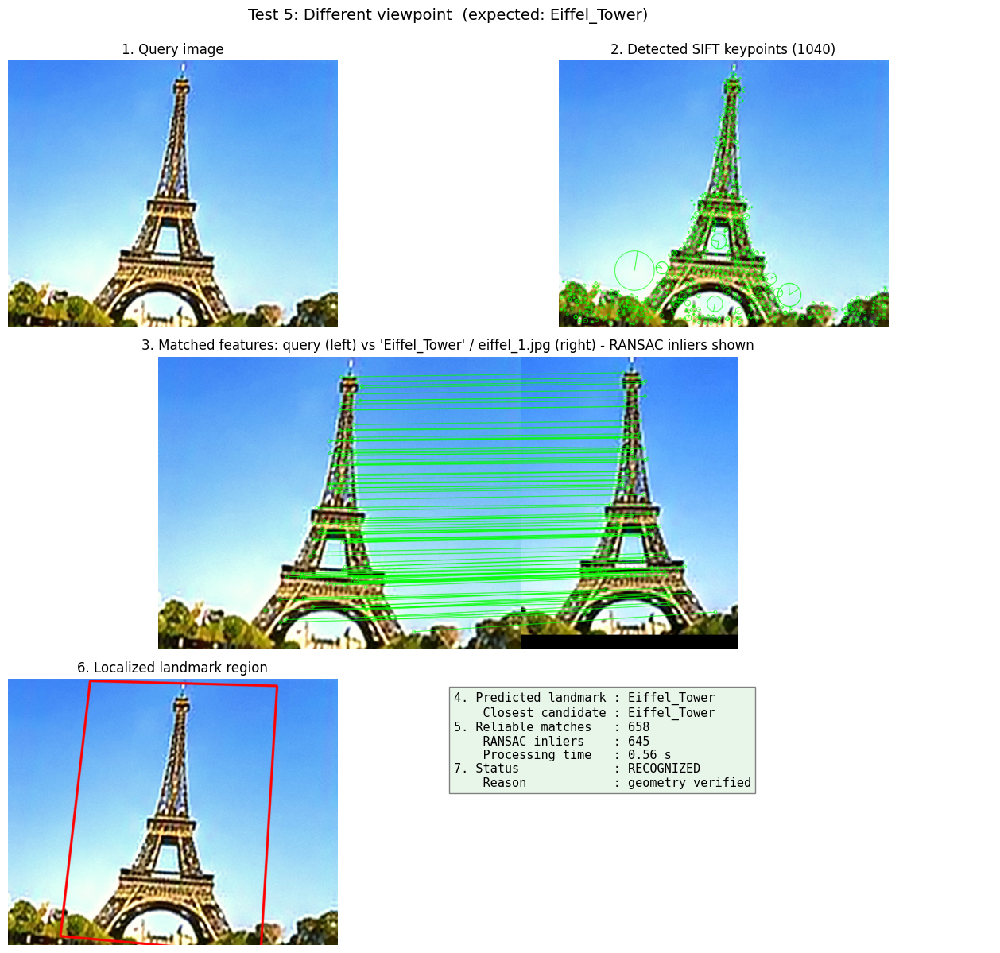

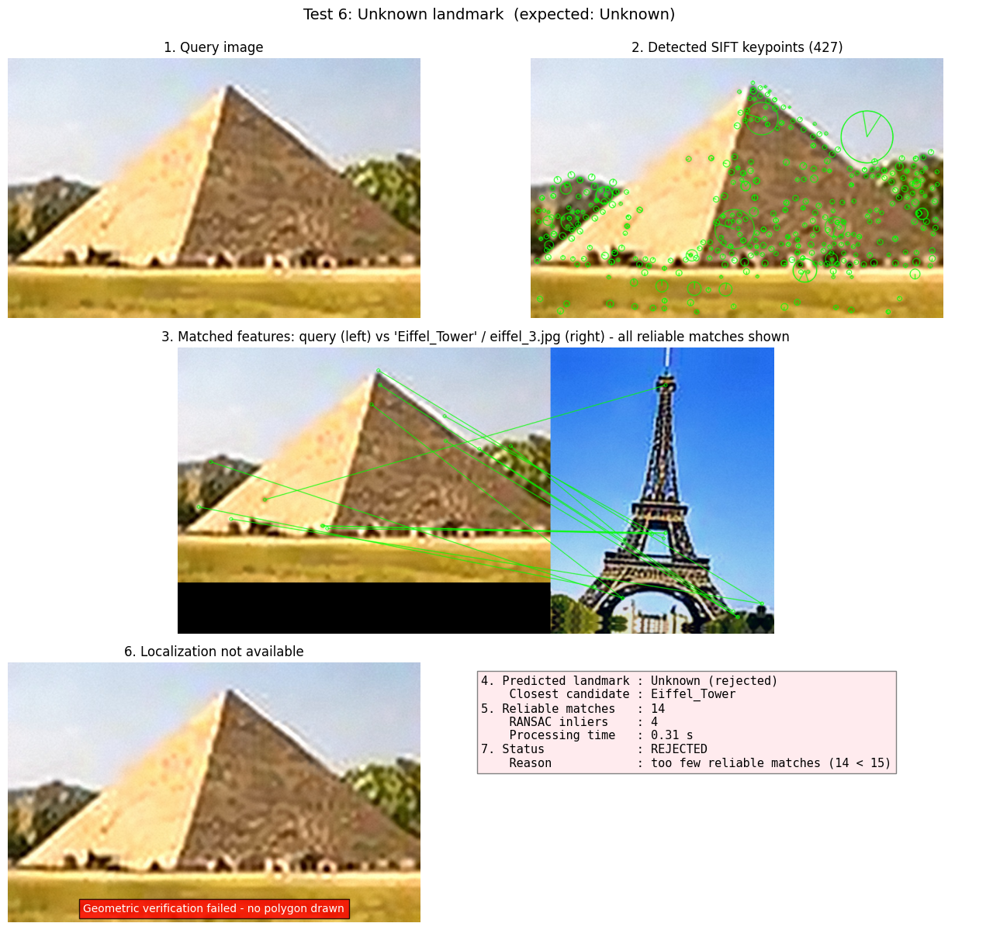

In [11]:
# ---- screenshots of every test (query, keypoints, matches, prediction, localisation, status) ----
for i, ((name, _, truth, _), res) in enumerate(zip(test_set, test_results), start=1):
    show_recognition(res, f"Test {i}: {name}  (expected: {truth})", save_as=f"task6_test{i}_{name.split()[0].lower()}.png")

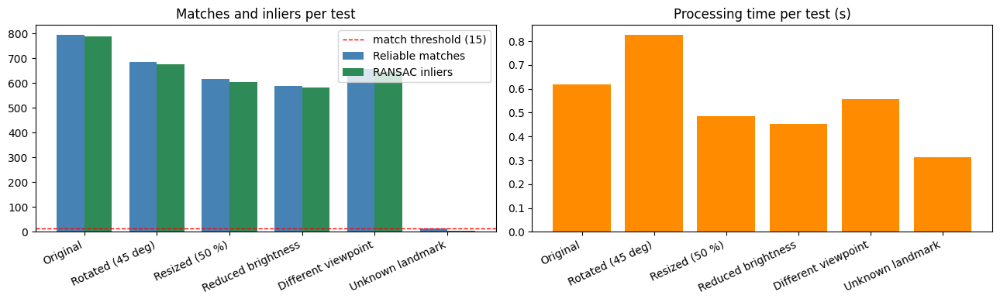

Correct decisions: 5/6   |   mean processing time: 0.54 s


In [12]:
# ---- summary chart ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(results_table))
w = 0.38
ax[0].bar(x - w / 2, results_table["Reliable matches"], w, label="Reliable matches", color="steelblue")
ax[0].bar(x + w / 2, results_table["RANSAC inliers"], w, label="RANSAC inliers", color="seagreen")
ax[0].axhline(MIN_GOOD_MATCHES, color="red", ls="--", lw=1, label=f"match threshold ({MIN_GOOD_MATCHES})")
ax[0].set_xticks(x); ax[0].set_xticklabels(results_table["Test"], rotation=25, ha="right")
ax[0].set_title("Matches and inliers per test"); ax[0].legend()
ax[1].bar(x, results_table["Time (s)"], color="darkorange")
ax[1].set_xticks(x); ax[1].set_xticklabels(results_table["Test"], rotation=25, ha="right")
ax[1].set_title("Processing time per test (s)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task6_summary.png", dpi=120)
plt.show()

n_correct = (results_table["Correct"] == "Yes").sum()
print(f"Correct decisions: {n_correct}/{len(results_table)}   |   mean processing time: {results_table['Time (s)'].mean():.2f} s")

### Extra: leave-one-out evaluation over the whole database
Each reference image is used once as a query while **that image is removed from the database**.
This gives an accuracy estimate over many real photos (not only the six test conditions) and shows how often the
rejection rules wrongly reject a known landmark.

In [13]:
def leave_one_out(database):
    rows = []
    for truth, entries in database.items():
        for e in entries:
            res = recognize(e["image"], database, exclude_path=e["path"])
            rows.append({"Landmark": truth, "Image": e["file"], "Predicted": res["predicted"],
                         "Closest candidate": res["closest_candidate"], "Reliable matches": res["n_good"],
                         "RANSAC inliers": res["inliers"],
                         "Outcome": "Correct" if res["predicted"] == truth else
                                    ("Wrong landmark" if res["recognized"] else "Rejected")})
    return pd.DataFrame(rows)


loo = leave_one_out(database)
display(loo)
summary = loo.groupby("Landmark")["Outcome"].value_counts().unstack(fill_value=0)
display(summary)
print(f"Overall leave-one-out accuracy: {(loo['Outcome'] == 'Correct').mean() * 100:.1f} %")
loo.to_csv(RESULTS_DIR / "leave_one_out_results.csv", index=False)

,Landmark,Image,Predicted,Closest candidate,Reliable matches,RANSAC inliers,Outcome
0,Colosseum,colosseum_1.jpg,Colosseum,Colosseum,706,686,Correct
1,Colosseum,colosseum_2.jpg,Colosseum,Colosseum,664,638,Correct
2,Colosseum,colosseum_3.jpg,Colosseum,Colosseum,710,688,Correct
3,Colosseum,colosseum_4.jpg,Colosseum,Colosseum,681,660,Correct
4,Eiffel_Tower,eiffel_1.jpg,Eiffel_Tower,Eiffel_Tower,653,650,Correct
5,Eiffel_Tower,eiffel_2.jpg,Eiffel_Tower,Eiffel_Tower,600,597,Correct
6,Eiffel_Tower,eiffel_3.jpg,Eiffel_Tower,Eiffel_Tower,657,652,Correct
7,Eiffel_Tower,eiffel_4.jpg,Eiffel_Tower,Eiffel_Tower,567,564,Correct
8,Great_Wall_of_China,great_wall_1.jpg,Great_Wall_of_China,Great_Wall_of_China,1328,1324,Correct
9,Great_Wall_of_China,great_wall_2.jpg,Great_Wall_of_China,Great_Wall_of_China,1330,1327,Correct


Outcome,Correct
Landmark,
Colosseum,4
Eiffel_Tower,4
Great_Wall_of_China,4
Statue_of_Liberty,4
Taj_Mahal,4


Overall leave-one-out accuracy: 100.0 %


## Discussion of system performance and limitations

*(Compare the statements below with the numbers in your own results table and adjust the wording to what you observed.)*

**Performance**
- SIFT keypoints are invariant to **scale and rotation** and partially invariant to **illumination**, so the rotated, resized and darkened
  versions of the query are expected to keep a high number of reliable matches and RANSAC inliers.
- **Lowe's ratio test** removes most ambiguous descriptor pairs; **RANSAC** then keeps only the matches that agree with one
  geometric transformation. This is why the system does not rely on the raw match count alone: a landmark is accepted only when it has enough matches,
  a valid homography with enough inliers (and a sufficient inlier ratio), and clearly more inliers than the runner-up.
- For the **unknown landmark** the few matches that survive the ratio test are inconsistent geometrically, so the threshold / RANSAC
  checks reject the image instead of forcing a wrong label.
- The **different viewpoint** test usually gives the fewest matches because SIFT is only invariant to affine changes, not to strong perspective changes.

**Limitations**
- Strong viewpoint changes, heavy occlusion (people, trees, scaffolding), very low light, motion blur or large changes in season / weather reduce the number of matches.
- Landmarks with repetitive texture (Great Wall, Colosseum arches) and very similar landmarks can create ambiguous matches.
- Brute-force matching against every reference image is `O(images × keypoints²)`; the processing time grows linearly with the database size.
  For large databases, FLANN / approximate nearest neighbours, a bag-of-visual-words index or learned descriptors would be needed.
- The thresholds (`MIN_GOOD_MATCHES`, `MIN_INLIERS`, margins) were chosen empirically and may need tuning for a different database.
- The projected polygon outlines the *reference image* region, so it is only an accurate landmark outline if the reference photo is tightly cropped around the landmark.
- Database quality matters: more reference views per landmark increase robustness.